# TP 2 — Exploration des données : l'exploration graphique


## Étape 0 — Mise en place


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

sns.set_theme(style='whitegrid')

iris = load_iris(as_frame=True)
df = iris.frame.copy()
df.columns = ['long_sepale', 'larg_sepale', 'long_petale', 'larg_petale', 'espece']
df['espece'] = df['espece'].map(dict(enumerate(iris.target_names)))

## Étape 1 — Premier regard sur les données

### Q1. Les 5 premières lignes, les dimensions et les types des colonnes

In [2]:
print("5 premières lignes :")
display(df.head())

print("Dimensions (lignes, colonnes) :", df.shape)

print("\nTypes des colonnes :")
print(df.dtypes)

5 premières lignes :


,long_sepale,larg_sepale,long_petale,larg_petale,espece
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dimensions (lignes, colonnes) : (150, 5)

Types des colonnes :
long_sepale    float64
larg_sepale    float64
long_petale    float64
larg_petale    float64
espece             str
dtype: object


### Q2. Nombre d'observations et de variables ; variables catégorielles / numériques

In [3]:
print("Observations :", df.shape[0])
print("Variables    :", df.shape[1])
df.info()

Observations : 150
Variables    : 5
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   long_sepale  150 non-null    float64
 1   larg_sepale  150 non-null    float64
 2   long_petale  150 non-null    float64
 3   larg_petale  150 non-null    float64
 4   espece       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


**Réponse :**
- **150 observations** (150 fleurs) et **5 variables**.
- **4 variables numériques** (continues, en cm) : `long_sepale`, `larg_sepale`, `long_petale`, `larg_petale`.
- **1 variable catégorielle** : `espece` (setosa, versicolor, virginica).

### Q3. Valeurs manquantes ?
On compte les valeurs manquantes de chaque colonne avec `isna().sum()`.

In [4]:
print(df.isna().sum())
print("\nTotal de valeurs manquantes :", df.isna().sum().sum())

long_sepale    0
larg_sepale    0
long_petale    0
larg_petale    0
espece         0
dtype: int64

Total de valeurs manquantes : 0


**Réponse :** `df.isna().sum()` compte les valeurs manquantes par colonne. Ici le total est **0** : le jeu de données est complet.

### Q4. Statistiques descriptives de `long_petale`

In [5]:
print(df['long_petale'].describe())
print()
print("Moyenne :", round(df['long_petale'].mean(), 2))
print("Médiane :", round(df['long_petale'].median(), 2))
print("Écart-type :", round(df['long_petale'].std(), 2))

count    150.000000
mean       3.758000
std        1.765298
min        1.000000
25%        1.600000
50%        4.350000
75%        5.100000
max        6.900000
Name: long_petale, dtype: float64

Moyenne : 3.76
Médiane : 4.35
Écart-type : 1.77


### Q5. Nombre de fleurs par espèce

In [6]:
print(df['espece'].value_counts())

espece
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


**Réponse :** 50 fleurs pour chacune des 3 espèces : le jeu de données est **équilibré**.

## Étape 2 — Variable catégorielle : parties d'un tout

Enquête sur la saison préférée de 200 élèves.

In [7]:
saisons = pd.Series({'Été': 90, 'Hiver': 60, 'Automne': 30, 'Printemps': 20})
saisons

Été          90
Hiver        60
Automne      30
Printemps    20
dtype: int64

### Q6. Diagramme en secteurs avec pourcentages

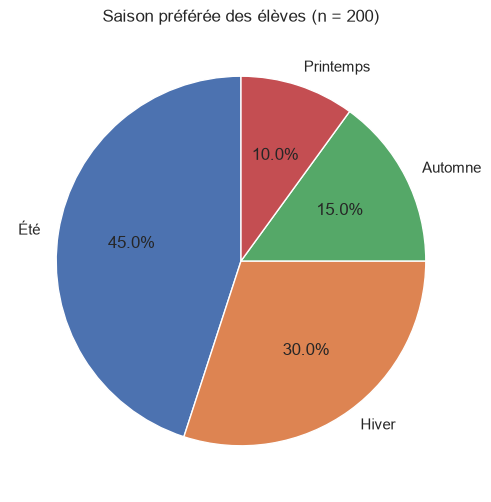

In [8]:
plt.figure(figsize=(6, 6))
plt.pie(saisons, labels=saisons.index, autopct='%1.1f%%', startangle=90)
plt.title("Saison préférée des élèves (n = 200)")
plt.show()

### Q7. Diagramme en barres trié par ordre décroissant

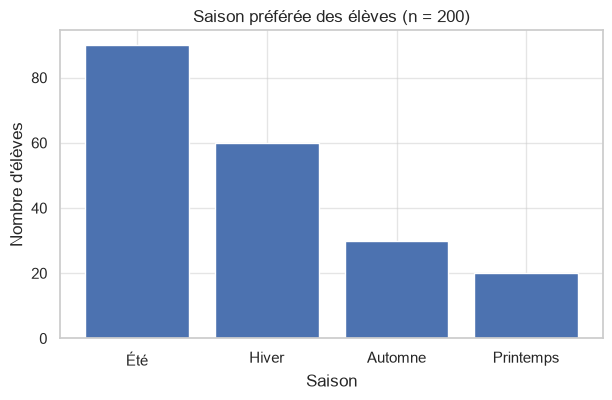

In [9]:
saisons_tri = saisons.sort_values(ascending=False)

plt.figure(figsize=(7, 4))
plt.bar(saisons_tri.index, saisons_tri.values)
plt.title("Saison préférée des élèves (n = 200)")
plt.xlabel("Saison")
plt.ylabel("Nombre d'élèves")
plt.show()

### Q8. Quel graphique pour comparer l'automne et le printemps ?
**Réponse :** le **diagramme en barres**. Les barres ont une base commune, donc on compare directement leurs **hauteurs** (30 contre 20). Dans le diagramme en secteurs, il faut comparer des angles ou des surfaces (15 % contre 10 %), ce qui est beaucoup moins précis à l'œil.

### Q9. Diagramme en secteurs de la variable `espece`

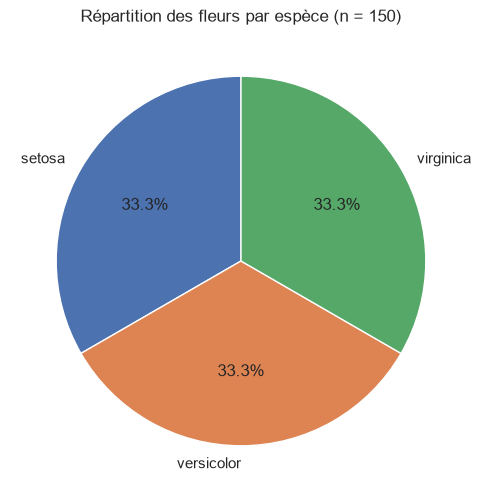

In [10]:
comptage = df['espece'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(comptage, labels=comptage.index, autopct='%1.1f%%', startangle=90)
plt.title("Répartition des fleurs par espèce (n = 150)")
plt.show()

**Constat :** les 3 parts sont égales (33,3 % chacune). Le graphique est **peu utile** ici : il n'apporte aucune information que la phrase « 50 fleurs par espèce » ne donne déjà.

## Étape 3 — Variable numérique : distribution

### Q10. Histogramme de `long_petale` (20 classes)

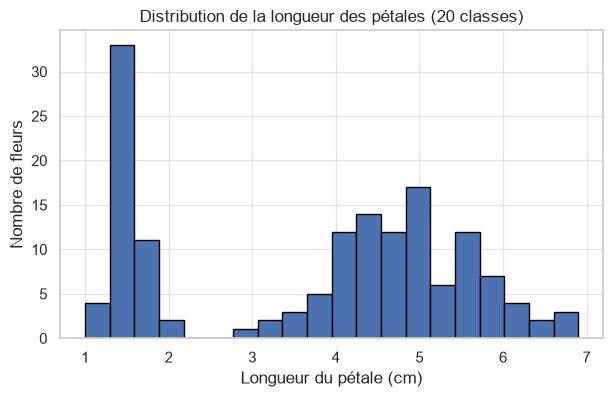

In [11]:
plt.figure(figsize=(7, 4))
plt.hist(df['long_petale'], bins=20, edgecolor='black')
plt.title("Distribution de la longueur des pétales (20 classes)")
plt.xlabel("Longueur du pétale (cm)")
plt.ylabel("Nombre de fleurs")
plt.show()

### Q11. Forme de la distribution
**Réponse :**
- La distribution a **deux bosses** (bimodale) : un premier groupe vers 1–2 cm, un second vers 4–6 cm.
- Elle n'est **pas symétrique**.
- Le groupe des petites valeurs est **isolé** : il y a un vide entre environ 2 et 3 cm.
- **Ce que cela suggère :** les données contiennent plusieurs sous-populations. Une espèce (setosa) a des pétales très courts, les deux autres ont des pétales plus longs.

### Q12. Effet du nombre de classes (5 puis 50)

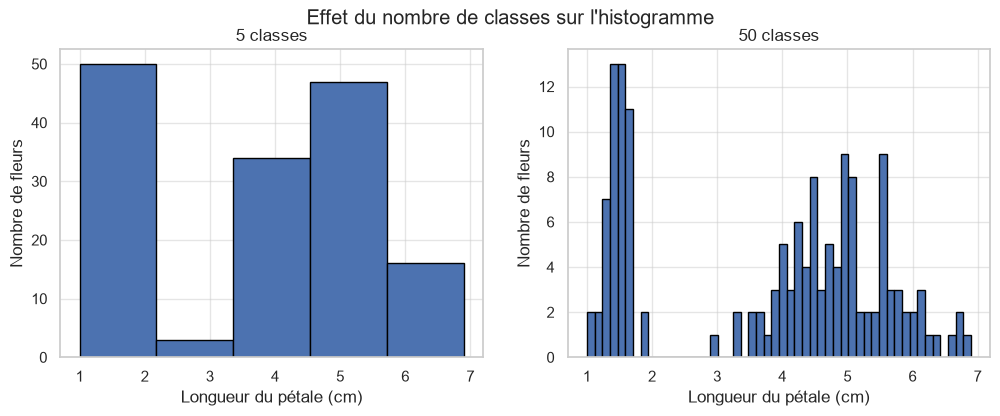

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['long_petale'], bins=5, edgecolor='black')
axes[0].set_title("5 classes")

axes[1].hist(df['long_petale'], bins=50, edgecolor='black')
axes[1].set_title("50 classes")

for ax in axes:
    ax.set_xlabel("Longueur du pétale (cm)")
    ax.set_ylabel("Nombre de fleurs")

fig.suptitle("Effet du nombre de classes sur l'histogramme")
plt.show()

**Réponse :**
- **Peu de classes (5)** : l'histogramme est trop lissé, on perd des détails (le vide entre les deux groupes est moins net).
- **Beaucoup de classes (50)** : l'histogramme devient irrégulier, avec beaucoup de petites barres et du bruit.
- Il faut donc choisir un nombre de classes **intermédiaire** (ici 15 à 20) pour bien voir la forme.

### Q13. Boîte à moustaches de `long_petale` par espèce

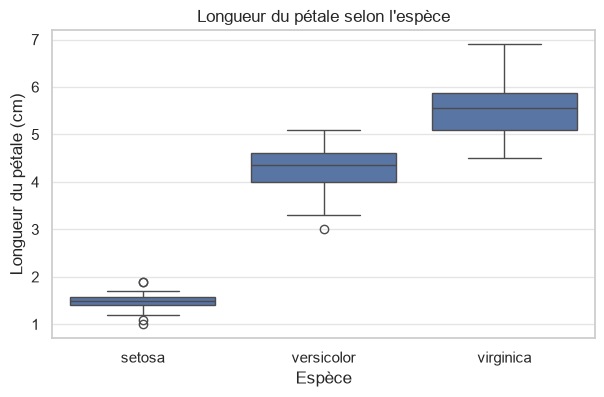

In [13]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='espece', y='long_petale')
plt.title("Longueur du pétale selon l'espèce")
plt.xlabel("Espèce")
plt.ylabel("Longueur du pétale (cm)")
plt.show()

### Q14. Médianes, homogénéité et chevauchement

In [14]:
resume = df.groupby('espece')['long_petale'].describe()
resume['IQR'] = resume['75%'] - resume['25%']
resume[['min', '25%', '50%', '75%', 'max', 'IQR']]

,min,25%,50%,75%,max,IQR
espece,,,,,,
setosa,1.0,1.4,1.50,1.575,1.9,0.175
versicolor,3.0,4.0,4.35,4.600,5.1,0.600
virginica,4.5,5.1,5.55,5.875,6.9,0.775


**Réponse :**
- **Médianes** : setosa ≈ 1,5 cm ; versicolor ≈ 4,35 cm ; virginica ≈ 5,55 cm.
- **Espèce la plus homogène** : **setosa**. Sa boîte est la plus étroite (IQR le plus petit), donc ses valeurs sont très proches les unes des autres.
- **Chevauchement** : setosa est totalement séparée des deux autres. Versicolor et virginica se chevauchent légèrement (quelques valeurs communes autour de 4,5 à 5,1 cm).

### Q15. Diagramme en violon

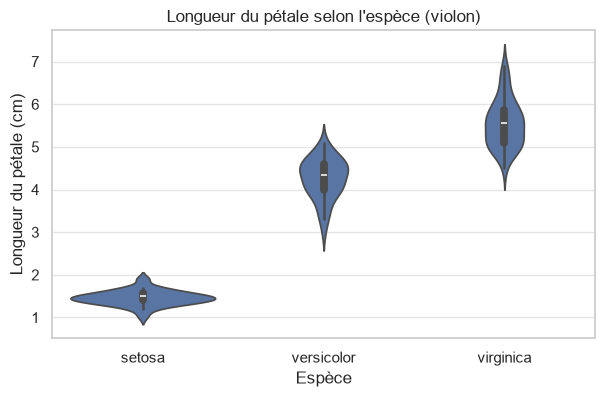

In [15]:
plt.figure(figsize=(7, 4))
sns.violinplot(data=df, x='espece', y='long_petale')
plt.title("Longueur du pétale selon l'espèce (violon)")
plt.xlabel("Espèce")
plt.ylabel("Longueur du pétale (cm)")
plt.show()

**Réponse :** le violon montre en plus la **forme complète de la distribution** (sa densité) : où les valeurs sont concentrées, si elle a une ou plusieurs bosses. La boîte à moustaches ne résume que 5 repères (min, quartiles, médiane, max).

## Étape 4 — Relations entre deux variables

### Q16. Nuage de points `larg_petale` en fonction de `long_petale`

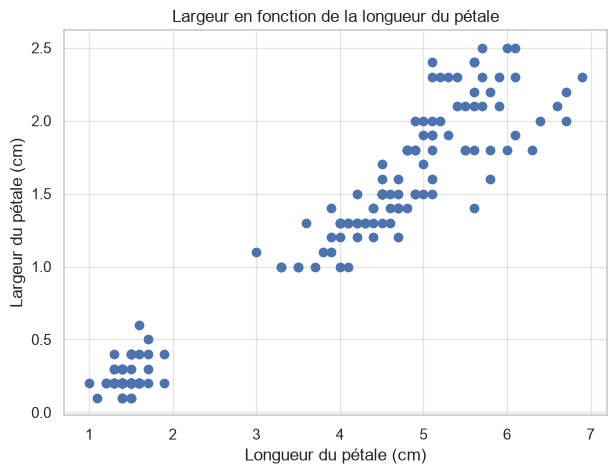

In [16]:
plt.figure(figsize=(7, 5))
plt.scatter(df['long_petale'], df['larg_petale'])
plt.title("Largeur en fonction de la longueur du pétale")
plt.xlabel("Longueur du pétale (cm)")
plt.ylabel("Largeur du pétale (cm)")
plt.show()

### Q17. Description de la relation
**Réponse :**
- **Sens** : positif (quand la longueur augmente, la largeur augmente aussi).
- **Forme** : à peu près linéaire.
- **Force** : très forte (les points sont proches d'une droite).
- **Regroupements** : oui, on voit **deux groupes** : un petit nuage en bas à gauche (pétales courts et étroits) et un grand nuage plus haut à droite.

### Q18. Nuage de points coloré par espèce

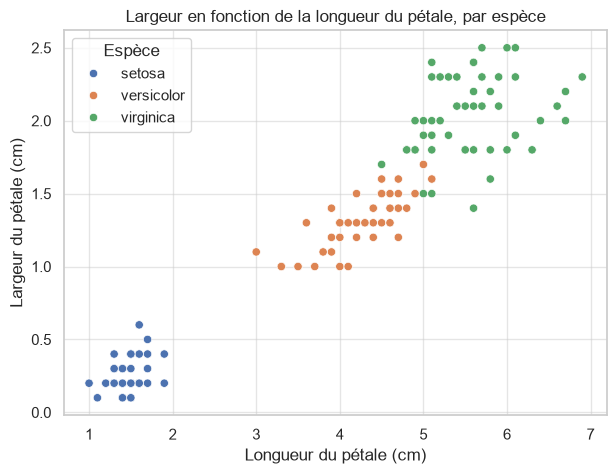

In [17]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='long_petale', y='larg_petale', hue='espece')
plt.title("Largeur en fonction de la longueur du pétale, par espèce")
plt.xlabel("Longueur du pétale (cm)")
plt.ylabel("Largeur du pétale (cm)")
plt.legend(title="Espèce")
plt.show()

**Réponse :** les groupes correspondent aux **espèces**. Setosa forme un groupe très distinct en bas à gauche ; versicolor et virginica forment deux nuages voisins, avec un petit chevauchement.

### Q19. Matrice de nuages de points (pairplot)

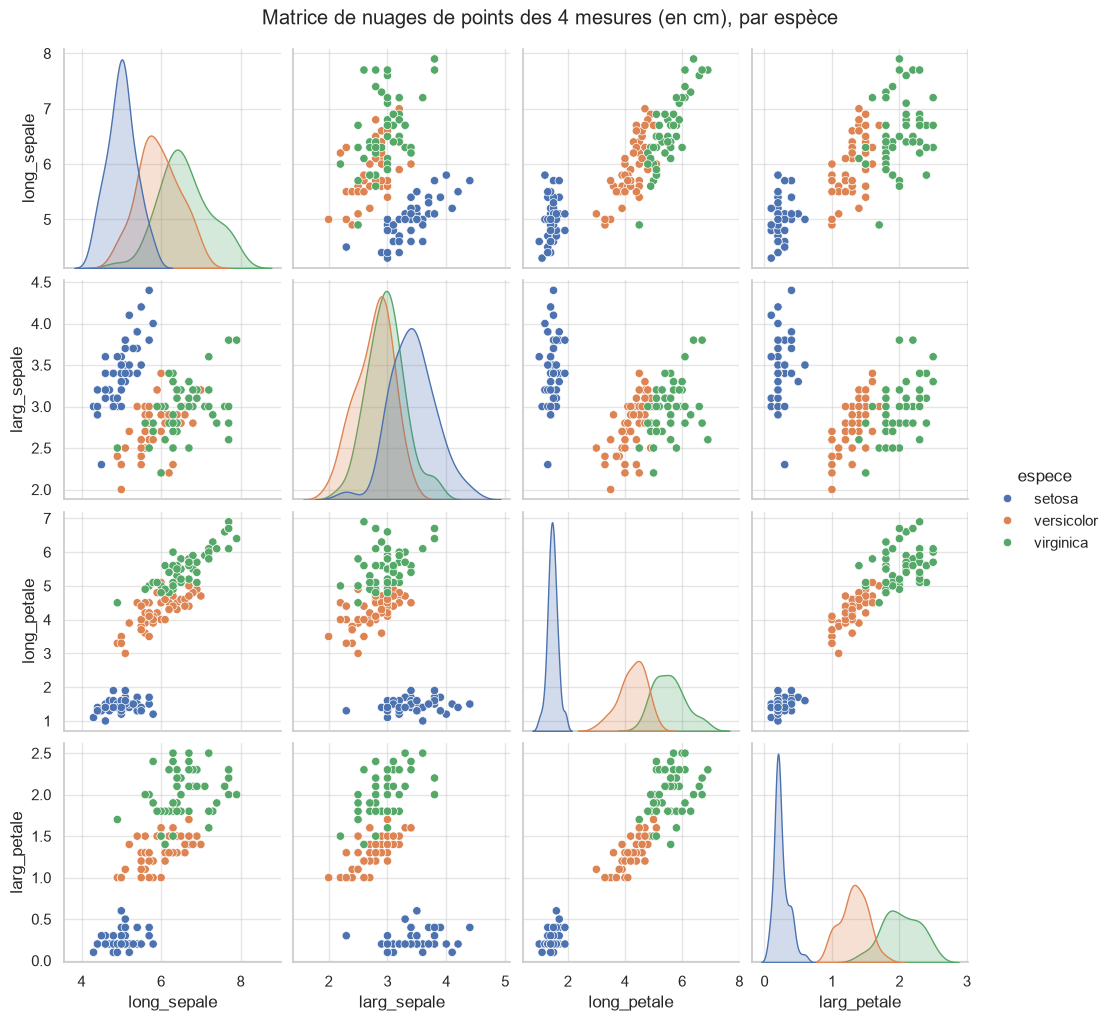

In [18]:
sns.pairplot(df, hue='espece')
plt.suptitle("Matrice de nuages de points des 4 mesures (en cm), par espèce", y=1.02)
plt.show()

### Q20. Quelle paire sépare le mieux / le moins bien les espèces ?
**Réponse :**
- **La mieux** : `long_petale` et `larg_petale` (les 3 espèces forment des groupes presque disjoints).
- **La moins bien** : `long_sepale` et `larg_sepale` (versicolor et virginica se mélangent beaucoup).

### Q21. `larg_sepale` en fonction de `long_sepale` : sans couleur, puis par espèce

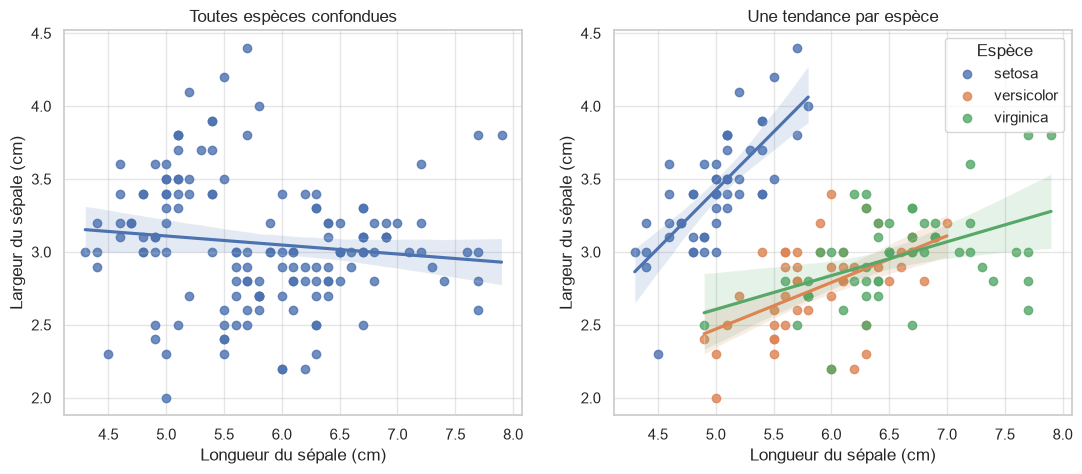

Corrélation globale : -0.12

Corrélation par espèce :
espece                 
setosa      long_sepale    0.74
versicolor  long_sepale    0.53
virginica   long_sepale    0.46
Name: larg_sepale, dtype: float64


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Sans couleur : une seule droite pour tout le monde
sns.regplot(data=df, x='long_sepale', y='larg_sepale', ax=axes[0])
axes[0].set_title("Toutes espèces confondues")

# Avec couleur : une droite par espèce
for nom, groupe in df.groupby('espece'):
    sns.regplot(data=groupe, x='long_sepale', y='larg_sepale', label=nom, ax=axes[1])
axes[1].set_title("Une tendance par espèce")
axes[1].legend(title="Espèce")

for ax in axes:
    ax.set_xlabel("Longueur du sépale (cm)")
    ax.set_ylabel("Largeur du sépale (cm)")
plt.show()

print("Corrélation globale :", round(df['long_sepale'].corr(df['larg_sepale']), 2))
print("\nCorrélation par espèce :")
print(df.groupby('espece')[['long_sepale', 'larg_sepale']].corr().iloc[0::2, -1].round(2))

**Réponse :** **non**, la tendance n'est pas la même.
- Globalement, la tendance est **presque nulle ou légèrement négative** (corrélation ≈ −0,12).
- À l'intérieur de **chaque espèce**, la tendance est **positive** (corrélation entre 0,45 et 0,75).

La tendance globale est donc trompeuse : elle vient du mélange des groupes.

## Étape 5 — Carte thermique des corrélations

### Q22. Matrice de corrélation

In [20]:
corr = df.drop(columns='espece').corr()
corr.round(2)

,long_sepale,larg_sepale,long_petale,larg_petale
long_sepale,1.00,-0.12,0.87,0.82
larg_sepale,-0.12,1.00,-0.43,-0.37
long_petale,0.87,-0.43,1.00,0.96
larg_petale,0.82,-0.37,0.96,1.00


### Q23. Carte thermique (échelle de −1 à 1, centrée sur 0)

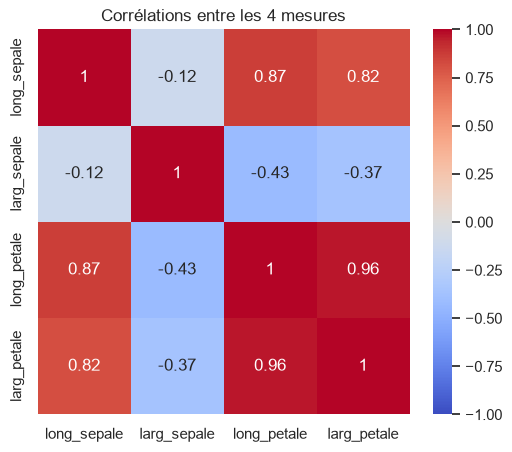

In [21]:
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title("Corrélations entre les 4 mesures")
plt.show()

### Q24. Paires fortement corrélées, corrélations négatives
**Réponse :**
- **Fortement corrélées** : `long_petale` et `larg_petale` (≈ 0,96), `long_petale` et `long_sepale` (≈ 0,87), `larg_petale` et `long_sepale` (≈ 0,82).
- **Corrélations négatives** : oui. `larg_sepale` est négativement corrélée avec les autres variables (≈ −0,12 avec `long_sepale`, ≈ −0,43 avec `long_petale`, ≈ −0,37 avec `larg_petale`).

### Q25. Pourquoi une corrélation globale peut être trompeuse
**Réponse :** d'après Q21, la corrélation globale entre `long_sepale` et `larg_sepale` est négative (≈ −0,12), alors qu'elle est **positive dans chaque espèce**. La corrélation globale **mélange des groupes** qui ont des niveaux moyens différents : setosa a des sépales plus courts mais plus larges. Ce mélange peut masquer, voire inverser, la vraie relation à l'intérieur des groupes (c'est le **paradoxe de Simpson**).
Il faut donc toujours regarder les nuages de points, par groupe si possible, avant de conclure à partir d'un seul coefficient.